In [1]:
import os
from pathlib import Path

os.chdir(Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd())

In [3]:
import GEOparse
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
GSE30219 = GEOparse.get_GEO(filepath='./data/raw/GSE30219_family.soft.gz')

25-May-2026 11:07:05 INFO GEOparse - Parsing ./data/raw/GSE30219_family.soft.gz: 
25-May-2026 11:07:05 DEBUG GEOparse - DATABASE: GeoMiame
25-May-2026 11:07:05 DEBUG GEOparse - SERIES: GSE30219
25-May-2026 11:07:05 DEBUG GEOparse - PLATFORM: GPL570
D:\Anaconda\Lib\site-packages\GEOparse\GEOparse.py:401: DtypeWarning: Columns (2) have mixed types. Specify dtype option on import or set low_memory=False.
  return read_csv(StringIO(data), index_col=None, sep="\t")
25-May-2026 11:07:06 DEBUG GEOparse - SAMPLE: GSM748053
25-May-2026 11:07:06 DEBUG GEOparse - SAMPLE: GSM748054
25-May-2026 11:07:06 DEBUG GEOparse - SAMPLE: GSM748055
25-May-2026 11:07:06 DEBUG GEOparse - SAMPLE: GSM748056
25-May-2026 11:07:06 DEBUG GEOparse - SAMPLE: GSM748057
25-May-2026 11:07:07 DEBUG GEOparse - SAMPLE: GSM748058
25-May-2026 11:07:07 DEBUG GEOparse - SAMPLE: GSM748059
25-May-2026 11:07:07 DEBUG GEOparse - SAMPLE: GSM748060
25-May-2026 11:07:07 DEBUG GEOparse - SAMPLE: GSM748061
25-May-2026 11:07:07 DEBUG GEOp

In [7]:
print(GSE30219.metadata)

{'title': ['"Off-context" gene expression in lung cancer identifies a group of metastatic-prone tumors'], 'geo_accession': ['GSE30219'], 'status': ['Public on May 24 2013'], 'submission_date': ['Jun 26 2011'], 'last_update_date': ['Mar 25 2019'], 'pubmed_id': ['23698379'], 'summary': ['An unexplored consequence of epigenetic alterations associated with cancer is the ectopic expression of tissue-restricted genes. Here, a new strategy was developed to decipher genome-wide expression data in search for these â€œoff-contextâ€ gene activations, which consisted first, in identifying a large number of tissue-specific genes normally epigenetically silenced in most somatic cells and second, in using them as cancer biomarkers on an â€œon/offâ€ basis. Applying this concept to analyze whole-genome transcriptome data in lung cancer, we discovered a specific group of 26 genes whose expression was a strong and independent predictor of poor prognosis in our cohort of 293 lung tumours, as well as in tw

In [9]:
for gsm_id, gsm in GSE30219.gsms.items():
    print(gsm_id, gsm.metadata['title'])

GSM748053 ['Lung cancer ADK1']
GSM748054 ['Lung cancer ADK2']
GSM748055 ['Lung cancer ADK3']
GSM748056 ['Lung Squamous Cell Carcinoma1']
GSM748057 ['Lung cancer ADK4']
GSM748058 ['Lung cancer ADK5']
GSM748059 ['Lung Squamous Cell Carcinoma2']
GSM748060 ['Non tumoral lung3']
GSM748061 ['Lung Squamous Cell Carcinoma3']
GSM748062 ['Lung Squamous Cell Carcinoma4']
GSM748063 ['Lung Squamous Cell Carcinoma5']
GSM748064 ['Lung cancer ADK6']
GSM748065 ['Lung Squamous Cell Carcinoma6']
GSM748066 ['Lung Squamous Cell Carcinoma7']
GSM748067 ['Lung Squamous Cell Carcinoma8']
GSM748068 ['Lung cancer ADK7']
GSM748069 ['Lung cancer Large Cell Carcinoma1']
GSM748070 ['Non tumoral lung4']
GSM748071 ['Lung cancer ADK8']
GSM748072 ['Lung Squamous Cell Carcinoma9']
GSM748073 ['Lung cancer_Other2']
GSM748074 ['Lung Squamous Cell Carcinoma10']
GSM748075 ['Lung cancer ADK9']
GSM748076 ['Lung Squamous Cell Carcinoma11']
GSM748077 ['Lung cancer ADK10']
GSM748078 ['Lung cancer ADK11']
GSM748079 ['Lung cancer AD

In [11]:
sample = list(GSE30219.gsms.values())[0]
print(sample.table.head())
print(sample.table.shape)

           ID_REF     VALUE
0  AFFX-BioB-5_at  7.626328
1  AFFX-BioB-M_at  8.147820
2  AFFX-BioB-3_at  7.349823
3  AFFX-BioC-5_at  8.760275
4  AFFX-BioC-3_at  8.963779
(54675, 2)


In [13]:
samples_of_interest = {}

for gsm_id, gsm in GSE30219.gsms.items():
    title = gsm.metadata['title'][0]
    if 'Small Cell Lung Carcinoma' in title:
        samples_of_interest[gsm_id] = 'SCLC'
    elif 'Non tumoral lung' in title:
        samples_of_interest[gsm_id] = 'Normal'

print('Selected samples:')
for gsm_id, group in samples_of_interest.items():
    print(f'{gsm_id}: {group}')

print(f'\nTotal: {len(samples_of_interest)}samples')

Selected samples:
GSM748060: Normal
GSM748070: Normal
GSM748107: Normal
GSM748118: Normal
GSM748129: Normal
GSM748153: Normal
GSM748158: Normal
GSM748168: Normal
GSM748176: Normal
GSM748184: Normal
GSM748209: SCLC
GSM748213: SCLC
GSM748215: SCLC
GSM748218: SCLC
GSM748219: SCLC
GSM748232: Normal
GSM748233: Normal
GSM748234: Normal
GSM748235: Normal
GSM748244: SCLC
GSM748245: SCLC
GSM748246: SCLC
GSM748247: SCLC
GSM748248: SCLC
GSM748249: SCLC
GSM748250: SCLC
GSM748251: SCLC
GSM748252: SCLC
GSM748253: SCLC
GSM748254: SCLC
GSM748255: SCLC
GSM748256: SCLC
GSM748257: SCLC
GSM748258: SCLC
GSM748265: SCLC

Total: 35samples


In [15]:
platform = list(GSE30219.gpls.values())[0]
print(platform.table.head())
print(platform.table.columns.tolist())

          ID  GB_ACC SPOT_ID Species Scientific Name Annotation Date  \
0  1007_s_at  U48705     NaN            Homo sapiens     Oct 6, 2014   
1    1053_at  M87338     NaN            Homo sapiens     Oct 6, 2014   
2     117_at  X51757     NaN            Homo sapiens     Oct 6, 2014   
3     121_at  X69699     NaN            Homo sapiens     Oct 6, 2014   
4  1255_g_at  L36861     NaN            Homo sapiens     Oct 6, 2014   

       Sequence Type                  Sequence Source  \
0  Exemplar sequence  Affymetrix Proprietary Database   
1  Exemplar sequence                          GenBank   
2  Exemplar sequence  Affymetrix Proprietary Database   
3  Exemplar sequence                          GenBank   
4  Exemplar sequence  Affymetrix Proprietary Database   

                                  Target Description Representative Public ID  \
0  U48705 /FEATURE=mRNA /DEFINITION=HSU48705 Huma...                   U48705   
1  M87338 /FEATURE= /DEFINITION=HUMA1SBU Human re...          

In [17]:
expr_matrix = pd.DataFrame()
for gsm_id in samples_of_interest.keys():
    sample = GSE30219.gsms[gsm_id]
    df = sample.table.set_index('ID_REF')['VALUE']
    df.name = gsm_id
    expr_matrix = pd.concat([expr_matrix, df], axis=1)

annotation = platform.table[['ID','Gene Symbol']]

annotation = annotation[annotation['Gene Symbol'].notna()]
annotation = annotation[annotation['Gene Symbol']!='']

annotation = annotation[~annotation['Gene Symbol'].str.contains('///')]

expr_matrix.index.name = 'ID'
expr_matrix = expr_matrix.merge(annotation, left_index=True, right_on='ID')
expr_matrix = expr_matrix.set_index('Gene Symbol').drop(columns='ID')

expr_matrix = expr_matrix.groupby('Gene Symbol').mean()

print(expr_matrix.shape)
print(expr_matrix.head())

(21655, 35)
             GSM748060  GSM748070  GSM748107  GSM748118  GSM748129  GSM748153  \
Gene Symbol                                                                     
A1BG          5.461304   5.854091   5.431093   5.493771   5.448174   5.460566   
A1BG-AS1      4.033533   4.186626   4.404230   4.064307   4.187209   4.379334   
A1CF          3.738128   3.801182   3.777091   3.786496   3.849066   3.877962   
A2M           8.578694   8.735854   8.791081   8.853886   8.378777   8.904442   
A2M-AS1       5.733086   6.056420   5.370221   5.741704   6.038870   5.394162   

             GSM748158  GSM748168  GSM748176  GSM748184  ...  GSM748250  \
Gene Symbol                                              ...              
A1BG          5.819776   5.870511   5.767713   5.745521  ...   5.563406   
A1BG-AS1      4.133750   4.412039   4.887472   4.373319  ...   4.396883   
A1CF          3.764402   3.840638   3.856911   3.749280  ...   3.737027   
A2M           8.786308   8.887970   8.791709 

In [19]:
print(f'Total NA values: {expr_matrix.isna().sum().sum()}')
print(f'\nNa value per sample:')
print(expr_matrix.isna().sum())

Total NA values: 0

Na value per sample:
GSM748060    0
GSM748070    0
GSM748107    0
GSM748118    0
GSM748129    0
GSM748153    0
GSM748158    0
GSM748168    0
GSM748176    0
GSM748184    0
GSM748209    0
GSM748213    0
GSM748215    0
GSM748218    0
GSM748219    0
GSM748232    0
GSM748233    0
GSM748234    0
GSM748235    0
GSM748244    0
GSM748245    0
GSM748246    0
GSM748247    0
GSM748248    0
GSM748249    0
GSM748250    0
GSM748251    0
GSM748252    0
GSM748253    0
GSM748254    0
GSM748255    0
GSM748256    0
GSM748257    0
GSM748258    0
GSM748265    0
dtype: int64


In [21]:
expr_matrix.to_csv('./data/processed/GSE30219_expression_matrix.csv')
print('Expression matirx saved!')

Expression matirx saved!


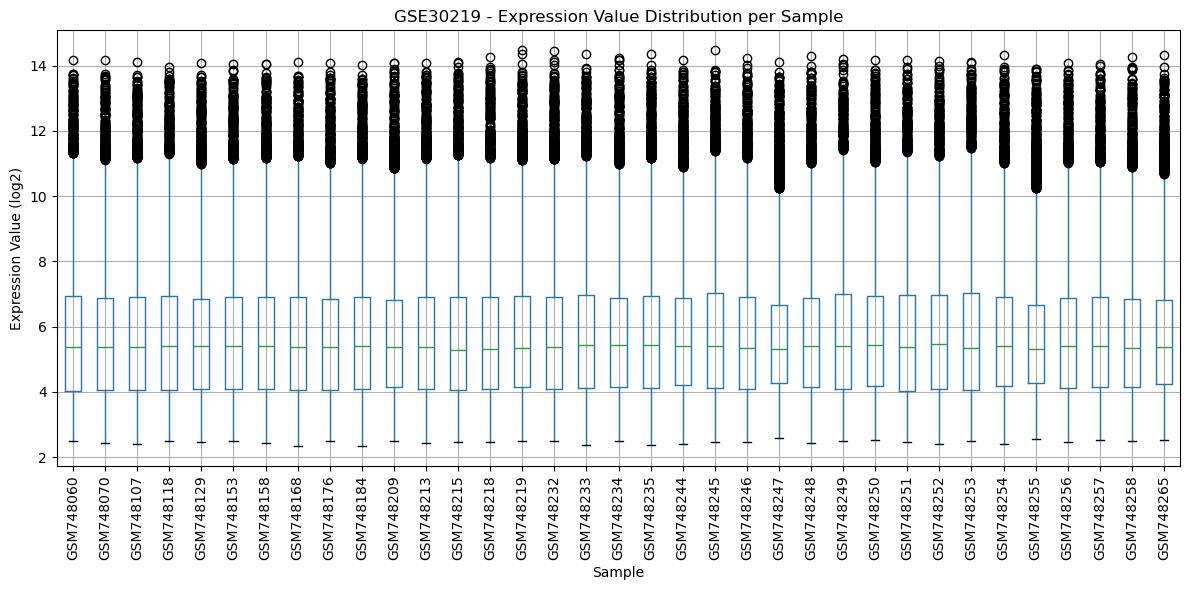

In [23]:
plt.figure(figsize=(12, 6))
expr_matrix.boxplot(rot=90)
plt.title('GSE30219 - Expression Value Distribution per Sample')
plt.ylabel('Expression Value (log2)')
plt.xlabel('Sample')
plt.tight_layout()
plt.savefig('./figures/GSE30219_boxplot.png', dpi=300)
plt.show()

In [25]:
metadata = pd.DataFrame({
    'sample_id': list(samples_of_interest.keys()),
    'group': list(samples_of_interest.values())
})
metadata = metadata.set_index('sample_id')
metadata.to_csv('./data/metadata/GSE30219_metadata.csv')
print(metadata)

            group
sample_id        
GSM748060  Normal
GSM748070  Normal
GSM748107  Normal
GSM748118  Normal
GSM748129  Normal
GSM748153  Normal
GSM748158  Normal
GSM748168  Normal
GSM748176  Normal
GSM748184  Normal
GSM748209    SCLC
GSM748213    SCLC
GSM748215    SCLC
GSM748218    SCLC
GSM748219    SCLC
GSM748232  Normal
GSM748233  Normal
GSM748234  Normal
GSM748235  Normal
GSM748244    SCLC
GSM748245    SCLC
GSM748246    SCLC
GSM748247    SCLC
GSM748248    SCLC
GSM748249    SCLC
GSM748250    SCLC
GSM748251    SCLC
GSM748252    SCLC
GSM748253    SCLC
GSM748254    SCLC
GSM748255    SCLC
GSM748256    SCLC
GSM748257    SCLC
GSM748258    SCLC
GSM748265    SCLC


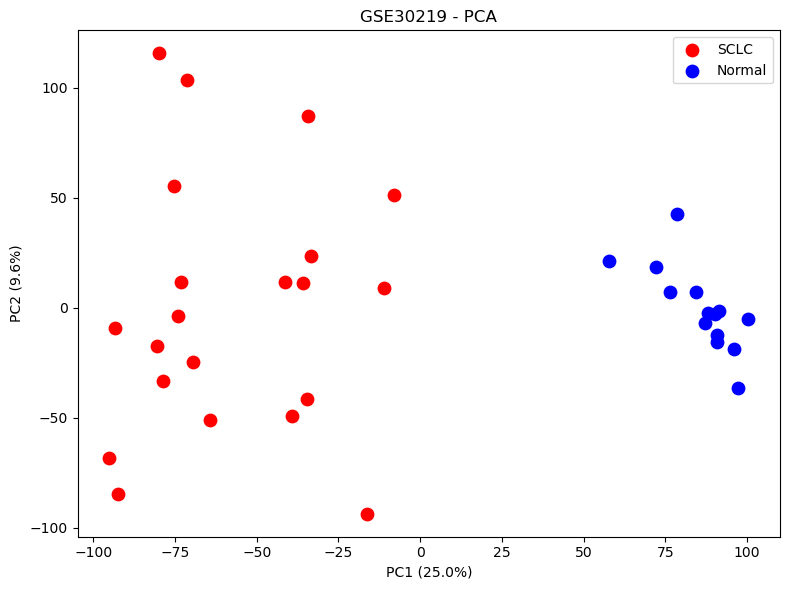

In [27]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

scaler = StandardScaler()
expr_scaled = scaler.fit_transform(expr_matrix.T)

pca = PCA(n_components=2)
pca_coords = pca.fit_transform(expr_scaled)

plt.figure(figsize=(8, 6))
colors = {'SCLC': 'red', 'Normal': 'blue'}
for group in ['SCLC', 'Normal']:
    mask = metadata['group'] == group
    plt.scatter(pca_coords[mask, 0], pca_coords[mask, 1],
                c=colors[group], label=group, s=80)

plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)')
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)')
plt.title('GSE30219 - PCA')
plt.legend()
plt.tight_layout()
plt.savefig('./figures/GSE30219_PCA.png', dpi=300)
plt.show()